In [3]:

import numpy  as  np
import matplotlib.pyplot  as  plt

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input,Dense
from tensorflow.keras.optimizers import Adam
import ssl
ssl._create_default_https_context = ssl._create_unverified_context

# MNISTデータの読み込み
#画像データは、描画がしやすいように28*28の行列

(x_train,_),(x_test,_)=mnist.load_data()

#データの前処理、正規化
x_train=x_train.astype('float32')/255.
x_test=x_test.astype('float32')/255.

x_train=x_train.reshape((len(x_train),np.prod(x_train.shape[1:])))
x_test=x_test.reshape((len(x_test),np.prod(x_test.shape[1:])))

#オートエンコーダのモデルを定義
input_img=Input(shape=(784,))

encoded=Dense(128,activation='relu')(input_img)
decoded=Dense(784,activation='sigmoid')(encoded)

autoencoder=Model(input_img,decoded)
autoencoder.compile(optimizer=Adam(),loss=('binary_crossentropy'))

autoencoder.fit(x_train,x_train,
                epochs=50,
                batch_size=256,
                shuffle=True,
                validation_data=(x_test,x_test)
)

encoded_imgs=autoencoder.predict(x_test)
decoded_imgs=autoencoder.predict(encoded_imgs)



11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.2118 - val_loss: 0.1347
Epoch 2/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.1181 - val_loss: 0.1034
Epoch 3/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0966 - val_loss: 0.0891
Epoch 4/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0860 - val_loss: 0.0815
Epoch 5/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0800 - val_loss: 0.0771
Epoch 6/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0763 - val_loss: 0.0743
Epoch 7/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0739 - val_loss: 0.0723
Epoch 8/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0721 - val_loss: 0.0710
Epoch 9/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0710 - val_loss: 0.0700
Epoch 10/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0701 - val_loss: 0.0693
Epoch 11/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0694 - val_loss: 0.0687
E

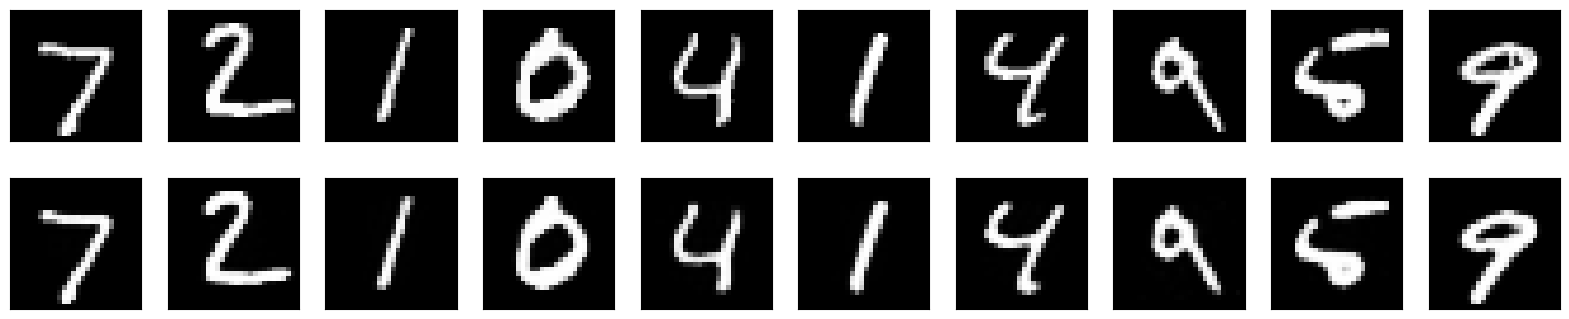

In [5]:
n=10
plt.figure(figsize=(20,4))

for i in range(n):

    #元の画像
    ax=plt.subplot(2,n,i+1)
    plt.imshow(x_test[i].reshape(28,28))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    #再構築された画像
    ax=plt.subplot(2,n,i+1+n)
    plt.imshow(decoded_imgs[i].reshape(28,28))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
plt.show()

In [12]:

import numpy  as  np
import pandas  as  pd
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow import keras
from tensorflow.keras import layers,models
from tensorflow.keras.utils import to_categorical

#Kerasに付属の手書き数字画像データをダウンロード
np.random.seed(0)
(X_train_base,labels_train_base),(test_x,test_y)=mnist.load_data()

train_x,valid_x,train_y,valid_y=train_test_split(X_train_base,labels_train_base,test_size=0.2)

train_x=train_x.reshape((48000,28,28,1))
valid_x=valid_x.reshape((12000,28,28,1))
test_x=test_x.reshape((10000,28,28,1))

#正規化
train_x=np.array(train_x).astype('float32')
valid_x=np.array(valid_x).astype('float32')
test_x=np.array(test_x).astype('float32')
train_x/=255
valid_x/=255
test_x/=255

#train_y,vaild_yをダミー変数化
train_y=to_categorical(train_y)
valid_y=to_categorical(valid_y)
#

model=models.Sequential()
model.add(layers.Conv2D(32,(3,3),activation='relu',input_shape=(28,28,1)))
model.add(layers.MaxPooling2D((2,2)))
model.add(layers.Conv2D(64,(3,3),activation='relu'))
model.add(layers.MaxPooling2D((2,2)))
model.add(layers.Conv2D(64,(3,3),activation='relu'))
model.add(layers.Flatten())
model.add(layers.Dense(64,activation='relu'))
#
model.add(layers.Dense(10,activation='softmax'))
#
model.compile(optimizer=tf.keras.optimizers.Adam(0.01),
                loss='categorical_crossentropy',
                metrics=['accuracy']
)
#
log=model.fit(train_x,train_y,epochs=100,batch_size=10,verbose=True,
                callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss',
                                                        min_delta=0,patience=10,verbose=1)],
                                                        validation_data=(valid_x,valid_y))

#
pred_test=np.argmax(model.predict(test_x),axis=1)
sum(pred_test==test_y)/len(pred_test)
#
#

Epoch 1/100
4800/4800 ━━━━━━━━━━━━━━━━━━━━ 51s 10ms/step - accuracy: 0.9343 - loss: 0.2326 - val_accuracy: 0.9463 - val_loss: 0.1855
Epoch 2/100
4800/4800 ━━━━━━━━━━━━━━━━━━━━ 45s 9ms/step - accuracy: 0.9495 - loss: 0.1932 - val_accuracy: 0.9612 - val_loss: 0.1645
Epoch 3/100
4800/4800 ━━━━━━━━━━━━━━━━━━━━ 46s 10ms/step - accuracy: 0.9544 - loss: 0.1995 - val_accuracy: 0.9594 - val_loss: 0.1961
Epoch 4/100
4800/4800 ━━━━━━━━━━━━━━━━━━━━ 47s 10ms/step - accuracy: 0.9531 - loss: 0.2202 - val_accuracy: 0.9385 - val_loss: 0.2748
Epoch 5/100
4800/4800 ━━━━━━━━━━━━━━━━━━━━ 45s 9ms/step - accuracy: 0.9529 - loss: 0.2288 - val_accuracy: 0.9240 - val_loss: 0.4543
Epoch 6/100
4800/4800 ━━━━━━━━━━━━━━━━━━━━ 46s 10ms/step - accuracy: 0.9453 - loss: 0.2651 - val_accuracy: 0.9470 - val_loss: 0.2462
Epoch 7/100
4800/4800 ━━━━━━━━━━━━━━━━━━━━ 45s 9ms/step - accuracy: 0.9415 - loss: 0.2876 - val_accuracy: 0.9375 - val_loss: 0.3278
Epoch 8/100
4800/4800 ━━━━━━━━━━━━━━━━━━━━ 45s 9ms/step - accuracy: 0.94

0.954